# S6B WT with the same UMAP dimensions as both mutants

WT uses the same nine/eight-metaclone groups, axes dimensions, fixed canvas width, fonts, markers and density scale as the executed mutant exports. WT retains Day 7, Day 14 and Day 27; one additional day row increases figure height without scaling any UMAP.

Environment: existing micromamba **chronoclone**, `/path/to/ChronoClone/.runtime/chronoclone`, kernel **chronoclone-paper**. Versions print below. Execution:
```sh
JUPYTER_PATH=/path/to/ChronoClone/.runtime/jupyter /path/to/ChronoClone/.runtime/chronoclone/bin/jupyter nbconvert --to notebook --execute --inplace --ExecutePreprocessor.kernel_name=chronoclone-paper /path/to/ChronoClone/analysis_workspace/singh/20260915_s6b_equal_umap/wt/s6b_wt_equal_umap.ipynb
```

Source: ../s6b_equal_umap.ipynb. Each authorized grid has its own cell and SVG/PNG stem. Gray background is rasterized; foreground and text are editable SVG.

In [1]:
import os
os.environ['MPLCONFIGDIR']='/path/to/ChronoClone/analysis_workspace/singh/20260915_s6b_equal_umap/wt/matplotlib_cache'

from pathlib import Path
import sys,platform,json,hashlib,datetime,warnings
import numpy as np
import pandas as pd
import h5py,scipy,matplotlib
from scipy.ndimage import gaussian_filter,map_coordinates
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from IPython.display import display
from PIL import Image
ROOT=Path('/path/to/ChronoClone')
OUT=ROOT/'analysis_workspace/singh/20260915_s6b_equal_umap/wt'
ENV=ROOT/'.runtime/chronoclone'
assert Path(sys.executable).resolve()==(ENV/'bin/python').resolve()
for directory in ['panels','tables','reports']:(OUT/directory).mkdir(parents=True,exist_ok=True)
execution_command=f'JUPYTER_PATH={ROOT}/.runtime/jupyter {ENV}/bin/jupyter nbconvert --to notebook --execute --inplace --ExecutePreprocessor.kernel_name=chronoclone-paper {OUT}/s6b_wt_equal_umap.ipynb'
environment={'name':'chronoclone','path':str(ENV),'manager':'existing micromamba-compatible environment; no mutation','kernel':'chronoclone-paper',
             'python':platform.python_version(),'numpy':np.__version__,'pandas':pd.__version__,'scipy':scipy.__version__,
             'h5py':h5py.__version__,'matplotlib':matplotlib.__version__,'execution_command':execution_command}
display(environment)
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':16,'axes.labelsize':16,'svg.fonttype':'none',
                     'savefig.facecolor':'white','figure.facecolor':'white','svg.hashsalt':'singh_weinreb_style_20260911'})
def sha256(path):
    digest=hashlib.sha256()
    with path.open('rb') as stream:
        for block in iter(lambda:stream.read(8*1024*1024),b''):digest.update(block)
    return digest.hexdigest()
CELL_SOURCE=ROOT/'analysis_workspace/singh/singh_reference_response_20260911/dynamics/tables/cells_resolved.csv'
MAP_SOURCE=ROOT/'data/processed/singh_strack/adata_valid_keep_all.h5ad'
PALETTE_SOURCE=ROOT/'analysis_workspace/singh/figure3_original_singh_landscape_20260811/tables/figure3_original_singh_clone_trajectory_umap_metaclone_label_positions.csv'
source_manifest=pd.DataFrame([{'source':str(p.relative_to(ROOT)),'bytes':p.stat().st_size,'sha256':sha256(p)} for p in [CELL_SOURCE,PALETTE_SOURCE]])
source_manifest.to_csv(OUT/'tables/source_manifest.csv',index=False)
display(source_manifest)



Matplotlib is building the font cache; this may take a moment.


{'name': 'chronoclone',
 'path': '/path/to/ChronoClone/.runtime/chronoclone',
 'manager': 'existing micromamba-compatible environment; no mutation',
 'kernel': 'chronoclone-paper',
 'python': '3.11.15',
 'numpy': '2.4.6',
 'pandas': '2.3.3',
 'scipy': '1.17.1',
 'h5py': '3.16.0',
 'matplotlib': '3.11.0',
 'execution_command': 'JUPYTER_PATH=/path/to/ChronoClone/.runtime/jupyter /path/to/ChronoClone/.runtime/chronoclone/bin/jupyter nbconvert --to notebook --execute --inplace --ExecutePreprocessor.kernel_name=chronoclone-paper /path/to/ChronoClone/analysis_workspace/singh/20260915_s6b_equal_umap/wt/s6b_wt_equal_umap.ipynb'}

,source,bytes,sha256
0,analysis_workspace/singh/singh_reference_response_2...,3949086,1c6107fb429938c2c0ecdf2ef0119a606c3df10caea1c5...
1,analysis_workspace/singh/figure3_original_singh_lan...,3430,df1b27dc2c3440de24f4c345764d2da73a2bece5a461d9...


In [2]:

# Read only the cell registry, HDF5 observation index and stored embedding. Do not access X/raw/layers.
cells=pd.read_csv(CELL_SOURCE,keep_default_na=False)
assert cells.cell_id.is_unique and cells.clone.ne('').all() and cells.clone_resolved.eq(True).all()
with h5py.File(MAP_SOURCE,'r') as source:
    index_key=source['obs'].attrs['_index']
    if isinstance(index_key,bytes):index_key=index_key.decode()
    full_ids=pd.Index(source['obs'][index_key].asstr()[:],name='cell_id')
    full_umap=np.asarray(source['obsm']['X_umap'][:,:2],dtype=np.float64)
assert full_ids.is_unique and len(full_ids)==96662 and full_umap.shape==(len(full_ids),2)
assert np.isfinite(full_umap).all()
positions=full_ids.get_indexer(cells.cell_id)
assert (positions>=0).all()
cells['umap1']=full_umap[positions,0];cells['umap2']=full_umap[positions,1]
assert np.array_equal(cells[['umap1','umap2']].to_numpy(),full_umap[positions])
MC_IDS=sorted(cells.mc.astype(int).unique().tolist())
assert len(MC_IDS)==17
SNAPSHOTS=[('WT','D7'),('WT','D14'),('WT','D27'),('Npm1c','D14'),('Npm1c','D27'),('Dnmt3a','D14'),('Dnmt3a','D27')]
assert set(zip(cells.arm,cells.day))==set(SNAPSHOTS)
assert cells.groupby('clone').mc.nunique().max()==1
assert not cells[['umap1','umap2']].isna().any().any()
print('Stored embedding SHA256:',hashlib.sha256(full_umap.tobytes()).hexdigest())
BANDWIDTH=0.4
GRID_SIZE=256
PLOT_XLIM=(full_umap[:,0].min()-0.4,full_umap[:,0].max()+0.4)
PLOT_YLIM=(full_umap[:,1].min()-0.4,full_umap[:,1].max()+0.4)
X_EDGES=np.linspace(full_umap[:,0].min()-4*BANDWIDTH,full_umap[:,0].max()+4*BANDWIDTH,GRID_SIZE+1)
Y_EDGES=np.linspace(full_umap[:,1].min()-4*BANDWIDTH,full_umap[:,1].max()+4*BANDWIDTH,GRID_SIZE+1)
DX=float(X_EDGES[1]-X_EDGES[0]);DY=float(Y_EDGES[1]-Y_EDGES[0])
X_CENTERS=(X_EDGES[:-1]+X_EDGES[1:])/2;Y_CENTERS=(Y_EDGES[:-1]+Y_EDGES[1:])/2
MIN_DENSITY_CELLS=20;MIN_DENSITY_FAMILIES=3
SPARSE_COLOR='#234B6C'
MC_LABEL_COLORS={0:'#f77189',1:'#f8763b',2:'#d28e32',3:'#b79932',4:'#9ea231',5:'#7caa31',6:'#31b345',7:'#34b081',9:'#35ae9a',10:'#36acad',11:'#38aac1',12:'#3aa6dd',13:'#7699f4',15:'#b087f4',16:'#df6df4',17:'#f563d8',19:'#f66ab2'}
assert set(MC_LABEL_COLORS)==set(MC_IDS)
palette_source=pd.read_csv(PALETTE_SOURCE)
assert dict(zip(palette_source.metaclone.astype(int),palette_source.label_color))==MC_LABEL_COLORS
display(palette_source[['metaclone','label_color']])
design={'fullmap_cells':len(full_ids),'registry_cells':len(cells),'unique_families':cells.clone.nunique(),
        'metaclones':MC_IDS,'snapshots':SNAPSHOTS,'expected_maps':len(MC_IDS)*len(SNAPSHOTS),
        'plot_xlim':PLOT_XLIM,'plot_ylim':PLOT_YLIM,'bandwidth_umap_units':BANDWIDTH,
        'grid_size':[GRID_SIZE,GRID_SIZE],'grid_dx':DX,'grid_dy':DY,
        'density_min_cells':MIN_DENSITY_CELLS,'density_min_families':MIN_DENSITY_FAMILIES,
        'density_weighting':'each observed cell equally weighted within its MC/arm/day snapshot',
        'source_coordinate_identity':'exact float64 values from original X_umap in source row order',
        'mc_label_palette':MC_LABEL_COLORS,'font_family':'DejaVu Sans',
        'expression_matrix_accessed':False,'umap_refitted':False,'background_rasterized_only':True}
(OUT/'reports/design.json').write_text(json.dumps(design,indent=2))
display(design)
display(cells.groupby(['arm','day']).agg(cells=('cell_id','size'),families=('clone','nunique')).reset_index())


Stored embedding SHA256: 0d556aba5fff8bf0ca9a4d2d7ae8d08870641b507ad99320ec56cf1ae5dbf445


,metaclone,label_color
0,0,#f77189
1,1,#f8763b
2,2,#d28e32
3,3,#b79932
4,4,#9ea231
5,5,#7caa31
6,6,#31b345
7,7,#34b081
8,9,#35ae9a
9,10,#36acad


{'fullmap_cells': 96662,
 'registry_cells': 14896,
 'unique_families': 1516,
 'metaclones': [0, 1, 2, 3, 4, 5, 6, 7, 9, 10, 11, 12, 13, 15, 16, 17, 19],
 'snapshots': [('WT', 'D7'),
  ('WT', 'D14'),
  ('WT', 'D27'),
  ('Npm1c', 'D14'),
  ('Npm1c', 'D27'),
  ('Dnmt3a', 'D14'),
  ('Dnmt3a', 'D27')],
 'expected_maps': 119,
 'plot_xlim': (np.float64(-5.9684041976928714), np.float64(7.454280757904053)),
 'plot_ylim': (np.float64(-9.033657455444336), np.float64(5.982400798797608)),
 'bandwidth_umap_units': 0.4,
 'grid_size': [256, 256],
 'grid_dx': 0.06180736310780066,
 'grid_dy': 0.06803147755563188,
 'density_min_cells': 20,
 'density_min_families': 3,
 'density_weighting': 'each observed cell equally weighted within its MC/arm/day snapshot',
 'source_coordinate_identity': 'exact float64 values from original X_umap in source row order',
 'mc_label_palette': {0: '#f77189',
  1: '#f8763b',
  2: '#d28e32',
  3: '#b79932',
  4: '#9ea231',
  5: '#7caa31',
  6: '#31b345',
  7: '#34b081',
  9: '#

,arm,day,cells,families
0,Dnmt3a,D14,1525,506
1,Dnmt3a,D27,1838,98
2,Npm1c,D14,828,280
3,Npm1c,D27,3543,68
4,WT,D14,3515,1512
5,WT,D27,934,138
6,WT,D7,2713,1514


In [3]:
# Reuse the audited common scale across WT and both mutant conditions.
scale_table=pd.read_csv(ROOT/'analysis_workspace/singh/singh_figure2b_grid_layout_20260911/tables/snapshot_support_and_density_scale.csv') if (ROOT/'analysis_workspace/singh/singh_figure2b_grid_layout_20260911/tables/snapshot_support_and_density_scale.csv').exists() else pd.read_csv(ROOT/'analysis_workspace/singh/singh_landscape_expansion_20260911/atlas/tables/snapshot_support_and_density_scale.csv')
DENSITY_MAX=float(scale_table.density_peak.max())
DENSITY_NORM=Normalize(vmin=0,vmax=DENSITY_MAX,clip=False)
print('Locked common density scale:',0,DENSITY_MAX)

REFERENCE_FIGURE=ROOT/'analysis_workspace/manuscript/chronoclone_sister_clone_revision_20260911/figures/figure_2b_selected_metaclone_maps.svg'
assert REFERENCE_FIGURE.exists()
print('Visual reference:',REFERENCE_FIGURE,sha256(REFERENCE_FIGURE))
REFERENCE_SCRIPT=ROOT/'analysis_workspace/manuscript/chronoclone_manuscript_panel_styling_20260907/build_0001_figure2b_2d_2g_styling_notebook.py'
REFERENCE_BACKGROUND=ROOT/'analysis_workspace/weinreb/weinreb_metaclone_cohesion_power_20260819/tables/iseh2026_registered_cell_state_umap_source.csv'
ref=pd.read_csv(REFERENCE_BACKGROUND,usecols=['cell_id','UMAP1','UMAP2']).drop_duplicates('cell_id')
reference_aspect=(ref.UMAP1.max()-ref.UMAP1.min()+1.6)/(ref.UMAP2.max()-ref.UMAP2.min()+1.6)
# Actual Figure 2B GridSpec geometry, followed by equal-aspect adjustment.
reference_box_width=7.2*(.995-.10)/(5+4*.02)
reference_box_height=7.8*(.94-.025)/(2+.33)/(3-2*.04)
REFERENCE_AXES_WIDTH_PT=min(reference_box_width,reference_box_height*reference_aspect)*72
print('Current Figure 2B axes width (pt):',REFERENCE_AXES_WIDTH_PT)
MARKER_AREA_MULTIPLIER=2.0  # the authors' subsequent explicit request: make dots bigger.
print('Foreground diameter multiplier over Figure 2B:',np.sqrt(MARKER_AREA_MULTIPLIER))
display(pd.DataFrame([{'path':str(p.relative_to(ROOT)),'sha256':sha256(p)} for p in [REFERENCE_FIGURE,REFERENCE_SCRIPT,REFERENCE_BACKGROUND]]))
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':13,'svg.hashsalt':'singh_figure2b_grid_20260911'})
grid_records=[];snapshot_records=[];axes_dimensions=[]
print('Authorized layout: metaclone columns, day rows; separate condition blocks; Day 7 only under WT.')


Locked common density scale: 0 0.3437506951697576
Visual reference: /path/to/ChronoClone/analysis_workspace/manuscript/chronoclone_sister_clone_revision_20260911/figures/figure_2b_selected_metaclone_maps.svg 7c1dd7887d7307d55c677c13bdf17d0ec546e4a1485a3754e514e6b0746af027
Current Figure 2B axes width (pt): 90.66692988852978
Foreground diameter multiplier over Figure 2B: 1.4142135623730951


,path,sha256
0,analysis_workspace/manuscript/chronoclone_sister_cl...,7c1dd7887d7307d55c677c13bdf17d0ec546e4a1485a37...
1,analysis_workspace/manuscript/chronoclone_manuscrip...,4626c25b3ffda4d5e7747a544aecb394eb428ffc930da9...
2,analysis_workspace/weinreb/weinreb_metaclone_cohesi...,4c5c532303ced39451a1de3bae67e6d75eb46358ee9450...


Authorized layout: metaclone columns, day rows; separate condition blocks; Day 7 only under WT.


## WT group 1

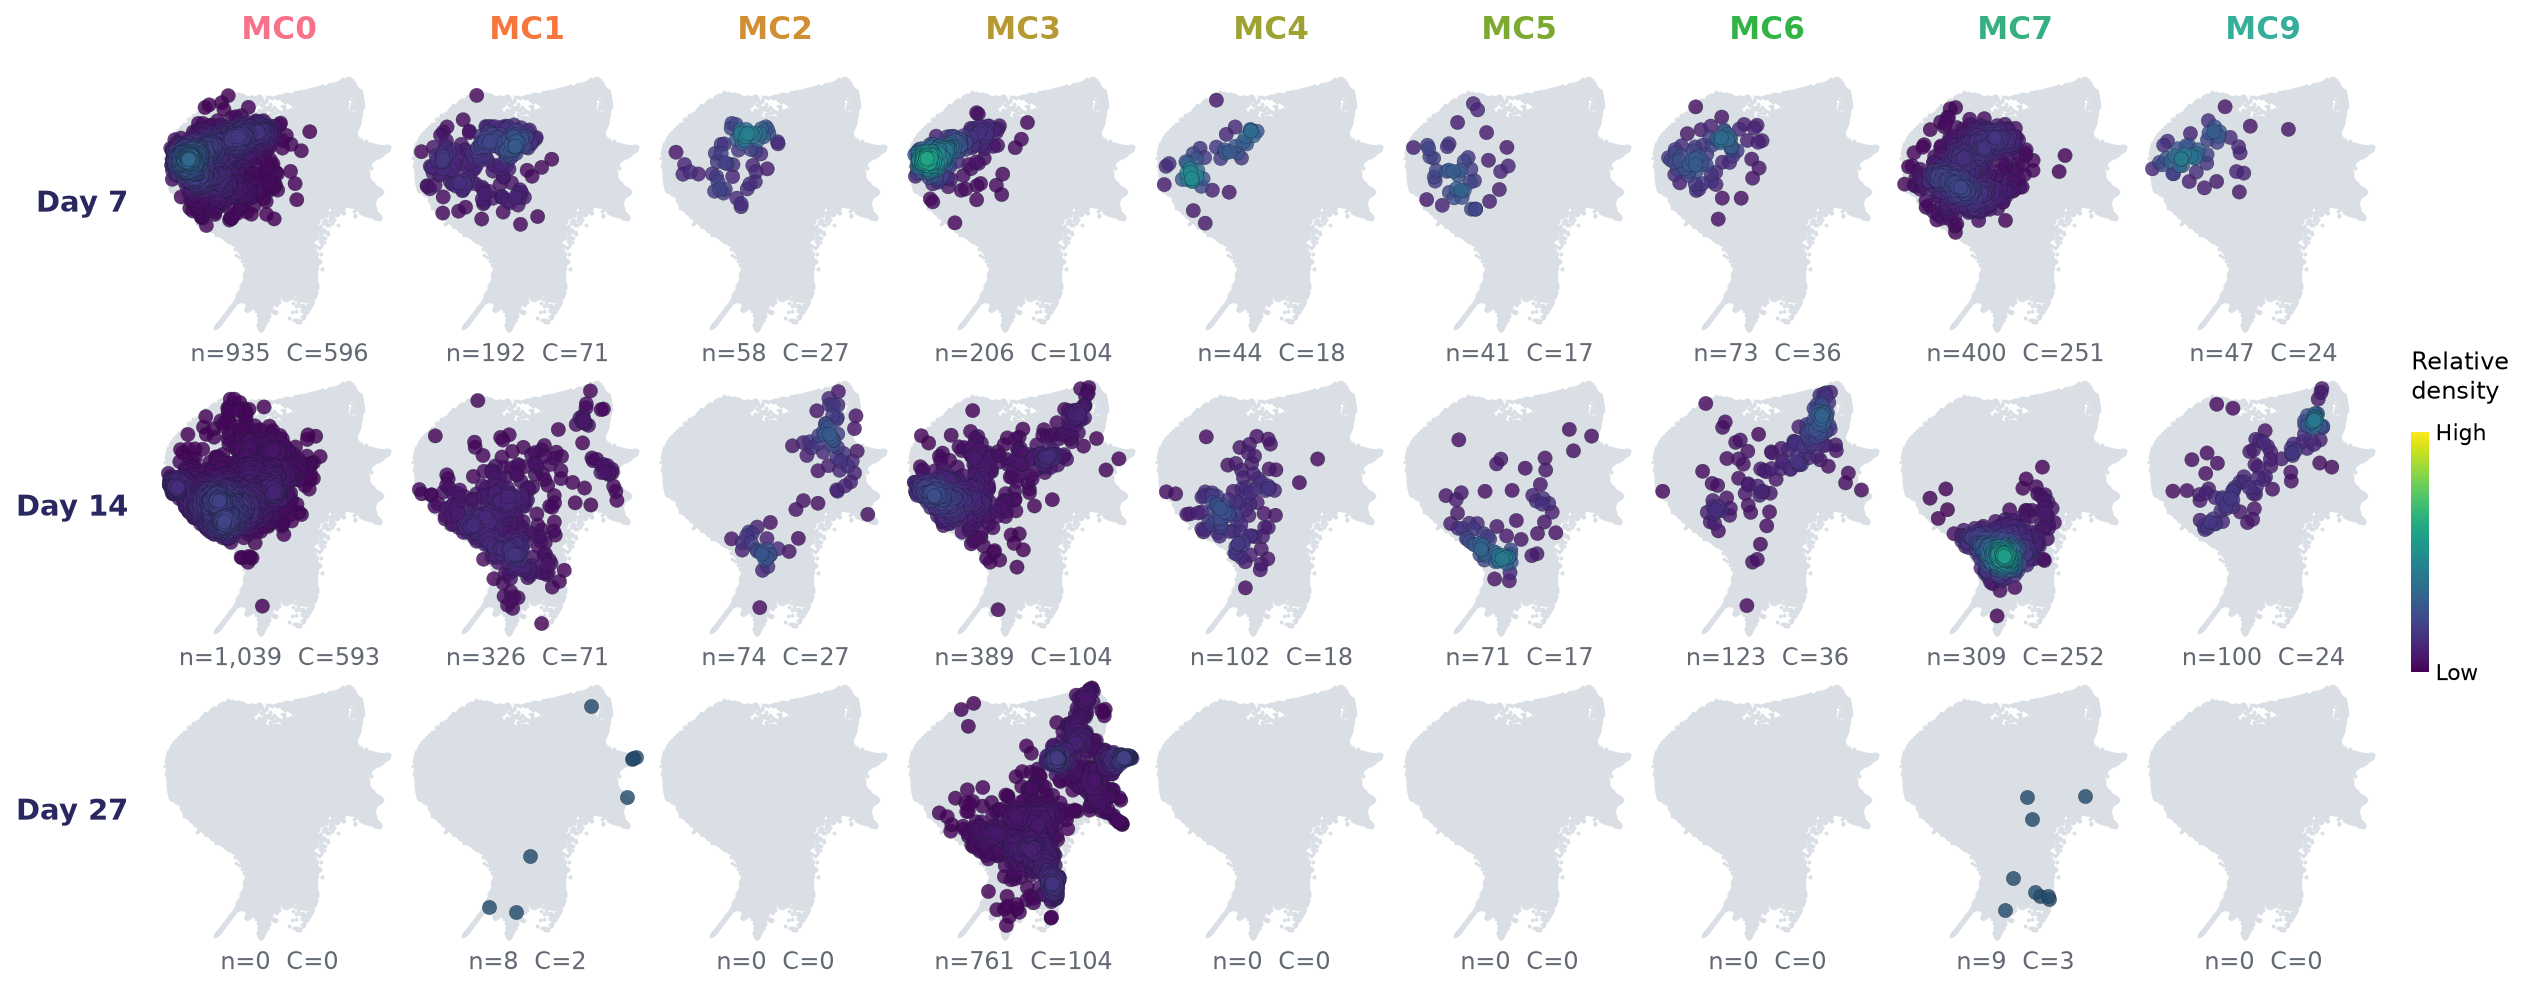

/path/to/ChronoClone/analysis_workspace/singh/20260915_s6b_equal_umap/wt/panels/atlas_wt_row_01.svg


In [4]:

# One authorized faceted figure: all calculations and full construction visible.
stem='atlas_wt_row_01';metaclones=[0, 1, 2, 3, 4, 5, 6, 7, 9];arms=['WT'];days=['D7','D14','D27'];column_dimension='mc'
columns=metaclones if column_dimension=='mc' else arms
nc=len(columns);nr=len(days)
previous_figures=set(plt.get_fignums())
fw=1.05+1.55*9+0.95;fh=0.45+1.90*nr  # Fixed width, exact WT map geometry
fig=plt.figure(figsize=(fw,fh),dpi=160,facecolor='white')
labels=[];axes_records=[]
for j,column in enumerate(columns):
    label=f'MC{column}' if column_dimension=='mc' else column
    labels.append(fig.text((1.05+1.55*(j+.5))/fw,1-0.08/fh,label,
                 ha='center',va='top',fontsize=14,fontweight='bold',
                 color=MC_LABEL_COLORS[column] if column_dimension=='mc' else '#29275f'))
for i,day in enumerate(days):
    bottom=fh-0.45-1.9*(i+1)+0.26
    labels.append(fig.text(0.88/fw,(bottom+.83)/fh,'Day '+day[1:],ha='right',va='center',
                          fontsize=13,fontweight='bold',color='#29275f'))
    for j,column in enumerate(columns):
        mc=column if column_dimension=='mc' else metaclones[0]
        arm=arms[0] if column_dimension=='mc' else column
        selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
        n=len(selected);family_count=selected.clone.nunique()
        eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
        locked=scale_table.loc[scale_table.mc.eq(mc)&scale_table.arm.eq(arm)&scale_table.day.eq(day)].iloc[0]
        assert (n,family_count)==(locked.cells,locked.families)
        if eligible:
            histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
            density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
            assert np.isclose(density.max(),locked.density_peak,rtol=1e-12)
            assert np.isclose(density.sum()*DX*DY,locked.density_integrated_mass,rtol=1e-12)
            point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
            order=np.argsort(point_density,kind='stable')
        else:
            point_density=None;order=np.arange(n)
        ax=fig.add_axes([(1.05+1.55*j)/fw,bottom/fh,1.52/fw,1.66/fh])
        ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
        fig.canvas.draw()
        width_pt=ax.get_window_extent().width/fig.dpi*72
        height_pt=ax.get_window_extent().height/fig.dpi*72
        axes_dimensions.append({'stem':stem,'mc':mc,'day':day,'width_pt':width_pt,'height_pt':height_pt})
        ratio=width_pt/REFERENCE_AXES_WIDTH_PT
        area=15*MARKER_AREA_MULTIPLIER*ratio**2;background_area=2.2*ratio**2;edge=.12*ratio
        assert np.isclose(np.sqrt(area)/width_pt,np.sqrt(15*MARKER_AREA_MULTIPLIER)/REFERENCE_AXES_WIDTH_PT,rtol=1e-12)
        ax.scatter(full_umap[:,0],full_umap[:,1],s=background_area,c='#d9dfe4',
                   linewidths=0,alpha=1,rasterized=True,zorder=0)
        if n:
            kwargs={'c':point_density[order],'cmap':'viridis','norm':DENSITY_NORM} if eligible else {'c':SPARSE_COLOR}
            ax.scatter(selected.umap1.to_numpy()[order],selected.umap2.to_numpy()[order],s=area,
                       **kwargs,edgecolors='#111827',linewidths=edge,alpha=.82,rasterized=False,zorder=2,clip_on=False)
        labels.append(fig.text((1.05+1.55*(j+.5))/fw,(bottom-.035)/fh,f'n={n:,}  C={family_count:,}',
                               ha='center',va='top',fontsize=11,color='#626972'))
        snapshot_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,
                                 'representation':locked.representation,'marker_ratio':np.sqrt(area)/width_pt,
                                 'density_peak':float(locked.density_peak)})
        axes_records.append(ax)
# Integral common-scale key, not a separate analytical panel.
bar=fig.add_axes([(1.05+1.55*9+.15)/fw,.32,.11/fw,1.5/fh])
cb=fig.colorbar(plt.cm.ScalarMappable(norm=DENSITY_NORM,cmap='viridis'),cax=bar)
cb.set_ticks([0,DENSITY_MAX]);cb.set_ticklabels(['Low','High']);cb.ax.tick_params(labelsize=10,length=0,pad=3)
cb.outline.set_visible(False)
labels.append(fig.text((1.05+1.55*9+.15)/fw,.32+1.5/fh+.025,'Relative\ndensity',fontsize=11,ha='left',va='bottom'))
fig.canvas.draw()
renderer=fig.canvas.get_renderer()
for label in labels:
    box=label.get_window_extent(renderer)
    assert box.x0>=0 and box.y0>=0 and box.x1<=fig.bbox.width and box.y1<=fig.bbox.height,(stem,label.get_text(),box)
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg=OUT/'panels'/f'{stem}.svg';png=svg.with_suffix('.png')
fig.savefig(svg);fig.savefig(png,dpi=240)
display(fig);plt.close(fig)
grid_records.append({'stem':stem,'columns':columns,'days':days,'column_dimension':column_dimension,
                     'width_in':fw,'height_in':fh,'svg_sha256':sha256(svg),'png_sha256':sha256(png)})
print(svg)


## WT group 2

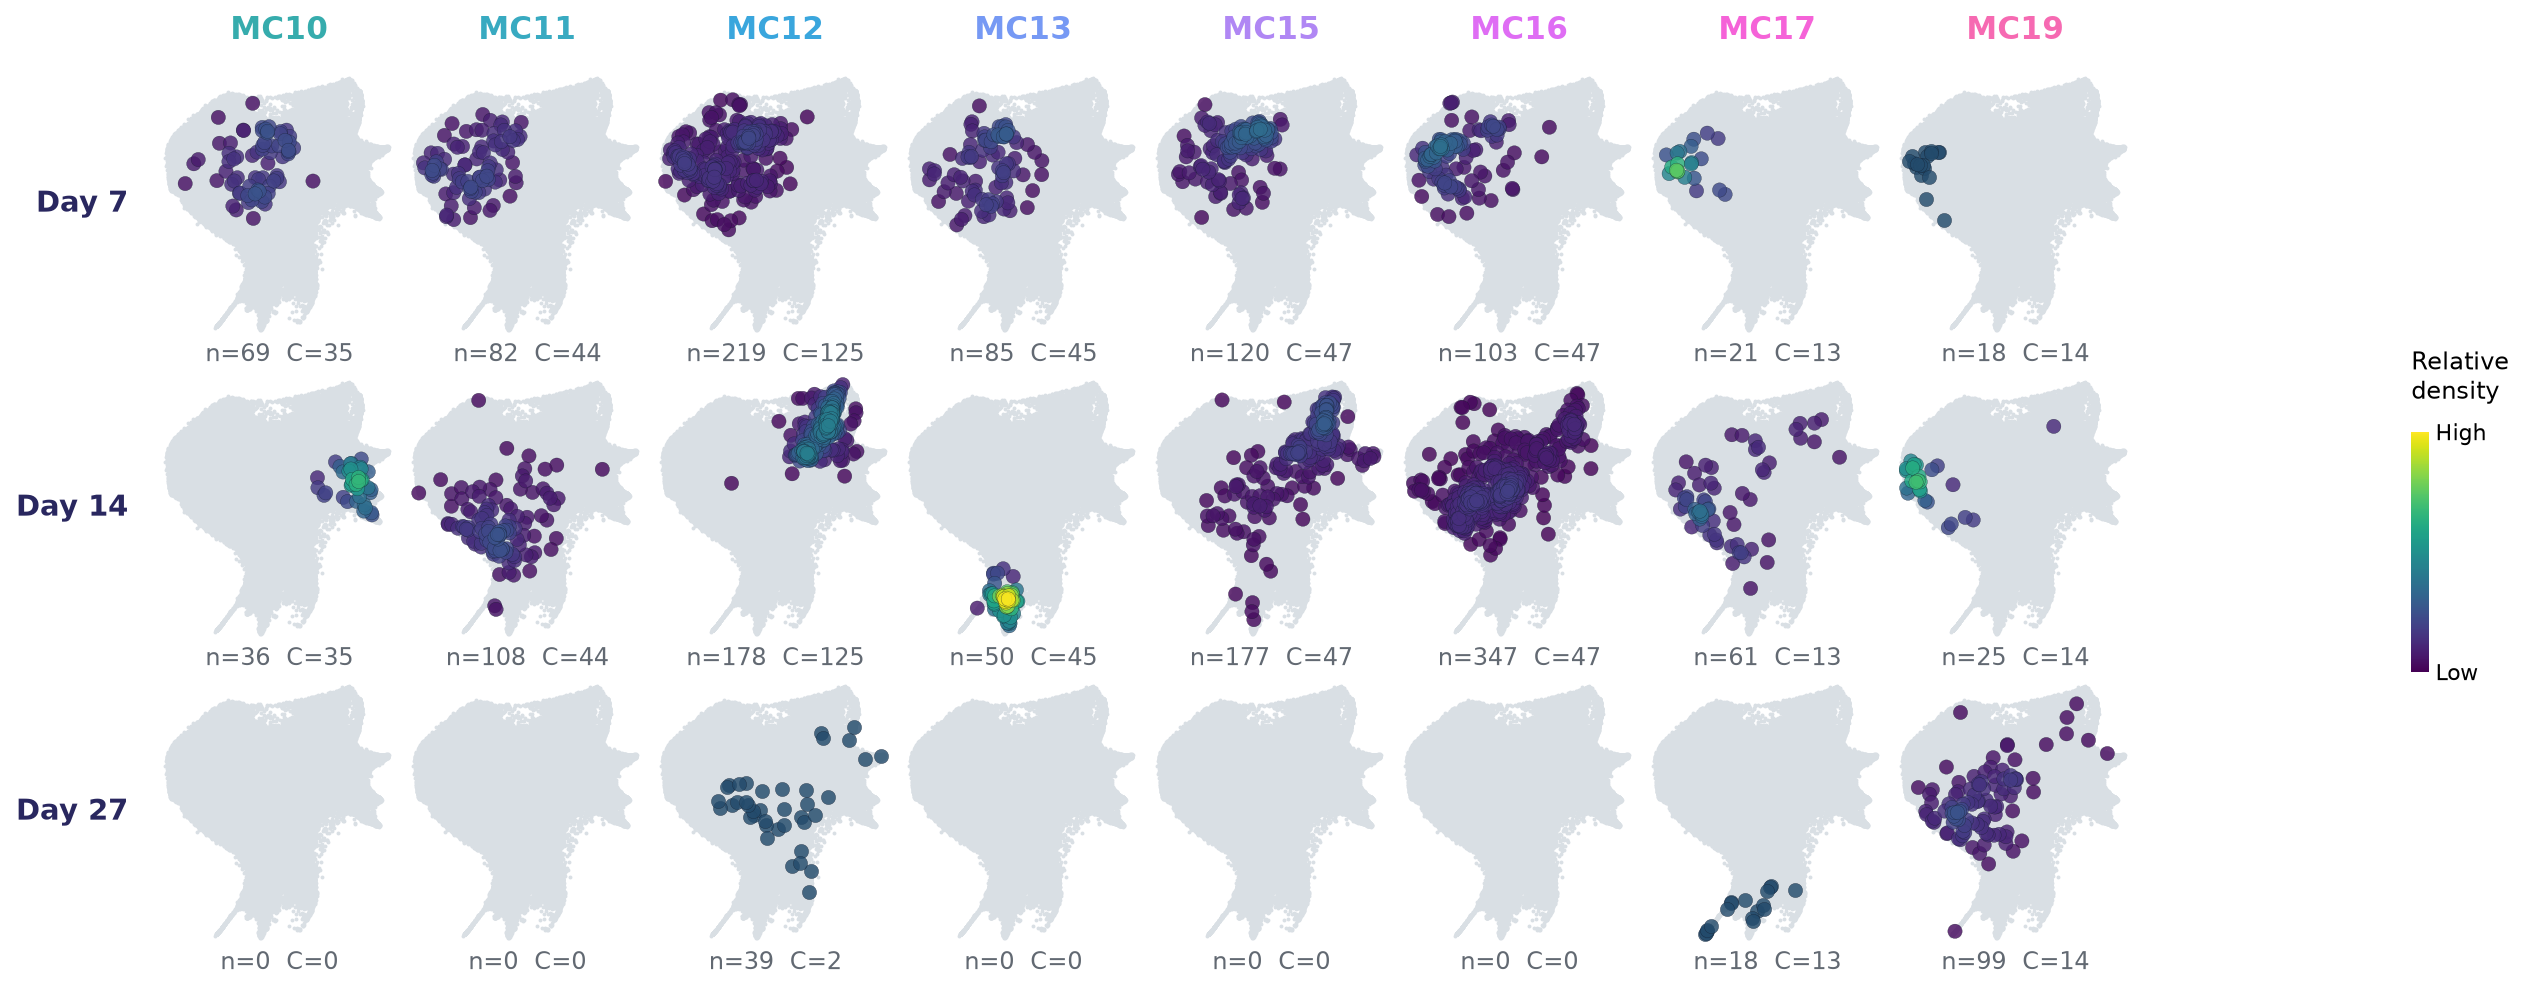

/path/to/ChronoClone/analysis_workspace/singh/20260915_s6b_equal_umap/wt/panels/atlas_wt_row_02.svg


In [5]:

# One authorized faceted figure: all calculations and full construction visible.
stem='atlas_wt_row_02';metaclones=[10, 11, 12, 13, 15, 16, 17, 19];arms=['WT'];days=['D7','D14','D27'];column_dimension='mc'
columns=metaclones if column_dimension=='mc' else arms
nc=len(columns);nr=len(days)
previous_figures=set(plt.get_fignums())
fw=1.05+1.55*9+0.95;fh=0.45+1.90*nr  # Fixed width, exact WT map geometry
fig=plt.figure(figsize=(fw,fh),dpi=160,facecolor='white')
labels=[];axes_records=[]
for j,column in enumerate(columns):
    label=f'MC{column}' if column_dimension=='mc' else column
    labels.append(fig.text((1.05+1.55*(j+.5))/fw,1-0.08/fh,label,
                 ha='center',va='top',fontsize=14,fontweight='bold',
                 color=MC_LABEL_COLORS[column] if column_dimension=='mc' else '#29275f'))
for i,day in enumerate(days):
    bottom=fh-0.45-1.9*(i+1)+0.26
    labels.append(fig.text(0.88/fw,(bottom+.83)/fh,'Day '+day[1:],ha='right',va='center',
                          fontsize=13,fontweight='bold',color='#29275f'))
    for j,column in enumerate(columns):
        mc=column if column_dimension=='mc' else metaclones[0]
        arm=arms[0] if column_dimension=='mc' else column
        selected=cells.loc[cells.mc.eq(mc)&cells.arm.eq(arm)&cells.day.eq(day)].copy()
        n=len(selected);family_count=selected.clone.nunique()
        eligible=n>=MIN_DENSITY_CELLS and family_count>=MIN_DENSITY_FAMILIES
        locked=scale_table.loc[scale_table.mc.eq(mc)&scale_table.arm.eq(arm)&scale_table.day.eq(day)].iloc[0]
        assert (n,family_count)==(locked.cells,locked.families)
        if eligible:
            histogram,_,_=np.histogram2d(selected.umap1,selected.umap2,bins=(X_EDGES,Y_EDGES))
            density=gaussian_filter(histogram/n,sigma=(BANDWIDTH/DX,BANDWIDTH/DY),mode='constant',truncate=4)/(DX*DY)
            assert np.isclose(density.max(),locked.density_peak,rtol=1e-12)
            assert np.isclose(density.sum()*DX*DY,locked.density_integrated_mass,rtol=1e-12)
            point_density=map_coordinates(density,np.vstack(((selected.umap1-X_CENTERS[0])/DX,(selected.umap2-Y_CENTERS[0])/DY)),order=1,mode='nearest')
            order=np.argsort(point_density,kind='stable')
        else:
            point_density=None;order=np.arange(n)
        ax=fig.add_axes([(1.05+1.55*j)/fw,bottom/fh,1.52/fw,1.66/fh])
        ax.set_xlim(PLOT_XLIM);ax.set_ylim(PLOT_YLIM);ax.set_aspect('equal');ax.set_axis_off()
        fig.canvas.draw()
        width_pt=ax.get_window_extent().width/fig.dpi*72
        height_pt=ax.get_window_extent().height/fig.dpi*72
        axes_dimensions.append({'stem':stem,'mc':mc,'day':day,'width_pt':width_pt,'height_pt':height_pt})
        ratio=width_pt/REFERENCE_AXES_WIDTH_PT
        area=15*MARKER_AREA_MULTIPLIER*ratio**2;background_area=2.2*ratio**2;edge=.12*ratio
        assert np.isclose(np.sqrt(area)/width_pt,np.sqrt(15*MARKER_AREA_MULTIPLIER)/REFERENCE_AXES_WIDTH_PT,rtol=1e-12)
        ax.scatter(full_umap[:,0],full_umap[:,1],s=background_area,c='#d9dfe4',
                   linewidths=0,alpha=1,rasterized=True,zorder=0)
        if n:
            kwargs={'c':point_density[order],'cmap':'viridis','norm':DENSITY_NORM} if eligible else {'c':SPARSE_COLOR}
            ax.scatter(selected.umap1.to_numpy()[order],selected.umap2.to_numpy()[order],s=area,
                       **kwargs,edgecolors='#111827',linewidths=edge,alpha=.82,rasterized=False,zorder=2,clip_on=False)
        labels.append(fig.text((1.05+1.55*(j+.5))/fw,(bottom-.035)/fh,f'n={n:,}  C={family_count:,}',
                               ha='center',va='top',fontsize=11,color='#626972'))
        snapshot_records.append({'stem':stem,'mc':mc,'arm':arm,'day':day,'cells':n,'families':family_count,
                                 'representation':locked.representation,'marker_ratio':np.sqrt(area)/width_pt,
                                 'density_peak':float(locked.density_peak)})
        axes_records.append(ax)
# Integral common-scale key, not a separate analytical panel.
bar=fig.add_axes([(1.05+1.55*9+.15)/fw,.32,.11/fw,1.5/fh])
cb=fig.colorbar(plt.cm.ScalarMappable(norm=DENSITY_NORM,cmap='viridis'),cax=bar)
cb.set_ticks([0,DENSITY_MAX]);cb.set_ticklabels(['Low','High']);cb.ax.tick_params(labelsize=10,length=0,pad=3)
cb.outline.set_visible(False)
labels.append(fig.text((1.05+1.55*9+.15)/fw,.32+1.5/fh+.025,'Relative\ndensity',fontsize=11,ha='left',va='bottom'))
fig.canvas.draw()
renderer=fig.canvas.get_renderer()
for label in labels:
    box=label.get_window_extent(renderer)
    assert box.x0>=0 and box.y0>=0 and box.x1<=fig.bbox.width and box.y1<=fig.bbox.height,(stem,label.get_text(),box)
assert set(plt.get_fignums())-previous_figures=={fig.number}
svg=OUT/'panels'/f'{stem}.svg';png=svg.with_suffix('.png')
fig.savefig(svg);fig.savefig(png,dpi=240)
display(fig);plt.close(fig)
grid_records.append({'stem':stem,'columns':columns,'days':days,'column_dimension':column_dimension,
                     'width_in':fw,'height_in':fh,'svg_sha256':sha256(svg),'png_sha256':sha256(png)})
print(svg)


In [6]:
dimensions=pd.DataFrame(axes_dimensions)
# Equal-aspect adjustment applied to the unchanged WT 1.52 × 1.66-inch box.
aspect=(PLOT_XLIM[1]-PLOT_XLIM[0])/(PLOT_YLIM[1]-PLOT_YLIM[0])
expected_width=min(1.52,1.66*aspect)*72
expected_height=min(1.66,1.52/aspect)*72
assert np.allclose(dimensions.width_pt,expected_width,rtol=1e-12)
assert np.allclose(dimensions.height_pt,expected_height,rtol=1e-12)
snapshots=pd.DataFrame(snapshot_records)
expected=scale_table.loc[scale_table.arm.eq('WT')].sort_values(['mc','arm','day']).reset_index(drop=True)
actual=snapshots.sort_values(['mc','arm','day']).reset_index(drop=True)
pd.testing.assert_frame_equal(actual[['mc','arm','day','cells','families','representation']],expected[['mc','arm','day','cells','families','representation']])
assert len(actual)==51 and not actual[['mc','arm','day']].duplicated().any()
assert len(grid_records)==2
sizes={r['stem']:Image.open(OUT/'panels'/f"{r['stem']}.png").size for r in grid_records}
assert len(set(sizes.values()))==1
snapshots.to_csv(OUT/'tables/snapshot_validation.csv',index=False)
dimensions.to_csv(OUT/'tables/umap_dimensions.csv',index=False)
qc={'umap_count':len(dimensions),'wt_source_width_pt':expected_width,'wt_source_height_pt':expected_height,'every_umap_same_size':True,'png_dimensions':sizes,'same_source_counts_density_and_scale':True,'visual_review':'pending','outputs':grid_records}
(OUT/'reports/validation.json').write_text(json.dumps(qc,indent=2))
display(qc)

mutant_dimensions=pd.read_csv(ROOT/'analysis_workspace/singh/20260915_s6b_equal_umap/tables/umap_dimensions.csv')
assert np.allclose(dimensions.width_pt,mutant_dimensions.width_pt.iloc[0],rtol=1e-12)
assert np.allclose(dimensions.height_pt,mutant_dimensions.height_pt.iloc[0],rtol=1e-12)
print('WT axes dimensions match every mutant UMAP; export widths match at 3828 pixels.')


{'umap_count': 51,
 'wt_source_width_pt': np.float64(106.83757872607782),
 'wt_source_height_pt': 119.52,
 'every_umap_same_size': True,
 'png_dimensions': {'atlas_wt_row_01': (3828, 1475),
  'atlas_wt_row_02': (3828, 1475)},
 'same_source_counts_density_and_scale': True,
 'visual_review': 'pending',
 'outputs': [{'stem': 'atlas_wt_row_01',
   'columns': [0, 1, 2, 3, 4, 5, 6, 7, 9],
   'days': ['D7', 'D14', 'D27'],
   'column_dimension': 'mc',
   'width_in': 15.950000000000001,
   'height_in': 6.1499999999999995,
   'svg_sha256': '007d2b61f54eb8a4a4d8ced9e6c82d3a423983c30efad883a107ada4481b4700',
   'png_sha256': '956c521d134aee9057921156fb06aa5b9f5390397d6d787afb9b40492f77413d'},
  {'stem': 'atlas_wt_row_02',
   'columns': [10, 11, 12, 13, 15, 16, 17, 19],
   'days': ['D7', 'D14', 'D27'],
   'column_dimension': 'mc',
   'width_in': 15.950000000000001,
   'height_in': 6.1499999999999995,
   'svg_sha256': 'f3735f1906571a8d90265a574a64bf0ffee7ff04c188ad019644e9f6add649a5',
   'png_sha256

WT axes dimensions match every mutant UMAP; export widths match at 3828 pixels.
